In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# [Cell 2] Setup and config
from pathlib import Path
import gc
import json
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import optuna
from IPython.display import display
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# -----------------------
# Experiment configuration
# -----------------------
SEED = 42
BACKBONES = ["densenet121", "resnet50", "efficientnet_b0"]   # shorten this list to save GPU budget
IMAGE_SIZE = 224
NUM_WORKERS = 2
USE_IMAGENET_WEIGHTS = True
EVAL_BATCH_SIZE = 64        # eval has no gradients, so a bigger batch is faster and does not change results
MIN_POS = 10                # min positives AND negatives needed to report a label's AUROC

LABELS = ["Effusion", "Cardiomegaly", "Pneumothorax", "Atelectasis",
          "Consolidation", "Mass", "Nodule"]

# Tuning split: 1/TUNE_SPLITS of the official train_val patients -> tuning (~11%)
TUNE_SPLITS = 9

# Stage 1: light-sample search
SEARCH_TRAIN_SIZE = 10_000
SEARCH_VAL_SIZE = 4_000
N_TRIALS = 12
TUNING_EPOCHS = 4

# Stage 2: final retrain of the winning config (sample sizes are capped at what the split holds)
FINAL_TRAIN_SIZE = 40_000
FINAL_VAL_SIZE = 8_000
FINAL_EPOCHS = 8

#STABILITY PARAMETERS
WARMUP_FRAC = 0.05
GRAD_CLIP_NORM = 1.0

STUDY_TAG = "v2"            # change to start a fresh Optuna study

# Output of dsai-nih-full-preprocessing, attached as an input to this notebook
PREPROCESSED_ROOT = Path("/kaggle/input/notebooks/t1f3001843/dsai-nih-preprocessing")
OUTPUT_DIR = Path("/kaggle/working/nih_multi_backbone_tuning")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

Device: cuda
GPU: Tesla T4


In [3]:
# [Cell 3] Load manifest and resolve shard paths
manifest_path = PREPROCESSED_ROOT / "outputs/processed/nih_full_manifest.csv"
if not manifest_path.exists():
    candidates = list(PREPROCESSED_ROOT.rglob("nih_full_manifest.csv"))
    if not candidates:
        raise FileNotFoundError(f"Could not find nih_full_manifest.csv under {PREPROCESSED_ROOT}")
    manifest_path = candidates[0]

print(f"Manifest: {manifest_path}")
manifest = pd.read_csv(manifest_path)

required_columns = {"official_split", "patient_id", "shard_index", "shard_path", *LABELS}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing columns: {sorted(missing_columns)}")

# One-time index of .npy shard files, keyed by (export_name, split, filename)
shard_files_by_key = {}
for path in PREPROCESSED_ROOT.rglob("*.npy"):
    shard_files_by_key[path.parts[-3:]] = path


def resolve_shard_path(value):
    candidate = Path(str(value))
    if candidate.is_file():
        return str(candidate)
    match = shard_files_by_key.get(candidate.parts[-3:])
    return str(match) if match is not None else None


manifest["shard_path"] = manifest["shard_path"].map(resolve_shard_path)
missing_shards = manifest["shard_path"].isna().sum()
if missing_shards:
    raise FileNotFoundError(f"Could not resolve {missing_shards:,} manifest rows to .npy shards.")

manifest["shard_index"] = pd.to_numeric(manifest["shard_index"], errors="coerce")
if manifest["shard_index"].isna().any():
    raise ValueError("Some manifest rows have a missing/non-numeric shard_index.")
manifest["shard_index"] = manifest["shard_index"].astype(int)
manifest["official_split"] = manifest["official_split"].astype(str).str.lower()
manifest["patient_id"] = manifest["patient_id"].astype(str)

for c in LABELS:
    if not manifest[c].isin([0, 1]).all():
        raise ValueError(f"Label column {c} has values other than 0/1.")

train_all = manifest[manifest["official_split"].eq("train_val")].copy()
test_all = manifest[manifest["official_split"].eq("test")].copy()
if train_all.empty or test_all.empty:
    raise ValueError(f"Expected non-empty train_val and test splits; got {len(train_all)} and {len(test_all)}. "
                     f"Splits present: {manifest['official_split'].unique().tolist()}")

print(manifest["official_split"].value_counts())
print(f"train_val: {len(train_all):,} images / {train_all['patient_id'].nunique():,} patients")
print(f"test     : {len(test_all):,} images / {test_all['patient_id'].nunique():,} patients")

Manifest: /kaggle/input/notebooks/t1f3001843/dsai-nih-preprocessing/outputs/processed/nih_full_manifest.csv
official_split
train_val    25045
test         11778
Name: count, dtype: int64
train_val: 25,045 images / 9,127 patients
test     : 11,778 images / 1,169 patients


In [4]:
# [Cell 4] Patient-level splits
RARE_FIRST = train_all[LABELS].sum().sort_values().index.tolist()   # rarest label first
print("Rarity order (rarest first):", RARE_FIRST)


def strata(df):
    """One stratum per row: the rarest positive label it has, or a final 'none' stratum."""
    pos = np.column_stack([df[c].eq(1).to_numpy() for c in RARE_FIRST])
    return np.where(pos.any(axis=1), pos.argmax(axis=1), len(RARE_FIRST))


def patient_holdout(df, n_splits):
    """Hold out ~1/n_splits of PATIENTS, stratified on rare labels. Returns (kept, held_out)."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    keep, hold = next(sgkf.split(df, strata(df), groups=df["patient_id"]))
    return df.iloc[keep].reset_index(drop=True), df.iloc[hold].reset_index(drop=True)


train_data, val_tune = patient_holdout(train_all, n_splits=TUNE_SPLITS)
test_data = test_all.reset_index(drop=True)

split_sets = {"train": train_data, "tune": val_tune, "test": test_data}
names = list(split_sets)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        shared = set(split_sets[a]["patient_id"]) & set(split_sets[b]["patient_id"])
        assert not shared, f"Patient overlap between {a} and {b}: {len(shared)} patients"

for name, d in split_sets.items():
    positives = {c: int(d[c].sum()) for c in RARE_FIRST}
    print(f"{name:6s} n={len(d):>8,}  patients={d['patient_id'].nunique():>7,}  positives={positives}")

Rarity order (rarest first): ['Cardiomegaly', 'Pneumothorax', 'Consolidation', 'Mass', 'Nodule', 'Atelectasis', 'Effusion']
train  n=  22,319  patients=  8,117  positives={'Cardiomegaly': 1500, 'Pneumothorax': 2332, 'Consolidation': 2536, 'Mass': 3625, 'Nodule': 4226, 'Atelectasis': 7351, 'Effusion': 7711}
tune   n=   2,726  patients=  1,010  positives={'Cardiomegaly': 207, 'Pneumothorax': 305, 'Consolidation': 316, 'Mass': 409, 'Nodule': 482, 'Atelectasis': 929, 'Effusion': 948}
test   n=  11,778  patients=  1,169  positives={'Cardiomegaly': 1069, 'Pneumothorax': 2665, 'Consolidation': 1815, 'Mass': 1748, 'Nodule': 1623, 'Atelectasis': 3279, 'Effusion': 4658}


In [5]:
# [Cell 5] Label diagnostics
def label_diagnostics(df, name):
    rows = []
    for c in LABELS:
        pos = int(df[c].eq(1).sum())
        rows.append({"label": c, "positive": pos, "negative": len(df) - pos,
                     "positive_rate": f"{pos / len(df):.2%}"})
    n_labels = df[LABELS].sum(axis=1)
    print(f"\n{name} (n={len(df):,}) | mean target labels per image: {n_labels.mean():.2f} | "
          f"images with 2+ labels: {(n_labels >= 2).mean():.1%} | images with none: {(n_labels == 0).mean():.1%}")
    display(pd.DataFrame(rows).set_index("label"))


for name, d in split_sets.items():
    label_diagnostics(d, name)


train (n=22,319) | mean target labels per image: 1.31 | images with 2+ labels: 25.8% | images with none: 0.0%


,positive,negative,positive_rate
label,,,
Effusion,7711,14608,34.55%
Cardiomegaly,1500,20819,6.72%
Pneumothorax,2332,19987,10.45%
Atelectasis,7351,14968,32.94%
Consolidation,2536,19783,11.36%
Mass,3625,18694,16.24%
Nodule,4226,18093,18.93%



tune (n=2,726) | mean target labels per image: 1.32 | images with 2+ labels: 26.0% | images with none: 0.0%


,positive,negative,positive_rate
label,,,
Effusion,948,1778,34.78%
Cardiomegaly,207,2519,7.59%
Pneumothorax,305,2421,11.19%
Atelectasis,929,1797,34.08%
Consolidation,316,2410,11.59%
Mass,409,2317,15.00%
Nodule,482,2244,17.68%



test (n=11,778) | mean target labels per image: 1.43 | images with 2+ labels: 34.0% | images with none: 0.0%


,positive,negative,positive_rate
label,,,
Effusion,4658,7120,39.55%
Cardiomegaly,1069,10709,9.08%
Pneumothorax,2665,9113,22.63%
Atelectasis,3279,8499,27.84%
Consolidation,1815,9963,15.41%
Mass,1748,10030,14.84%
Nodule,1623,10155,13.78%


In [6]:
# [Cell 6] Float targets and light samples for the two stages
for d in split_sets.values():
    for c in LABELS:
        d[c] = d[c].astype(np.float32)


def sample_frame(df, n):
    return df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)


search_train = sample_frame(train_data, SEARCH_TRAIN_SIZE)
search_val = sample_frame(val_tune, SEARCH_VAL_SIZE)
final_train = sample_frame(train_data, FINAL_TRAIN_SIZE)
final_val = sample_frame(val_tune, FINAL_VAL_SIZE)

for name, d in [("search_train", search_train), ("search_val", search_val),
                ("final_train", final_train), ("final_val", final_val)]:
    pos = {c: int(d[c].sum()) for c in LABELS}
    print(f"{name:13s} n={len(d):>7,}  positives={pos}")

search_train  n= 10,000  positives={'Effusion': 3436, 'Cardiomegaly': 684, 'Pneumothorax': 1058, 'Atelectasis': 3300, 'Consolidation': 1142, 'Mass': 1593, 'Nodule': 1920}
search_val    n=  2,726  positives={'Effusion': 948, 'Cardiomegaly': 207, 'Pneumothorax': 305, 'Atelectasis': 929, 'Consolidation': 316, 'Mass': 409, 'Nodule': 482}
final_train   n= 22,319  positives={'Effusion': 7711, 'Cardiomegaly': 1500, 'Pneumothorax': 2332, 'Atelectasis': 7351, 'Consolidation': 2536, 'Mass': 3625, 'Nodule': 4226}
final_val     n=  2,726  positives={'Effusion': 948, 'Cardiomegaly': 207, 'Pneumothorax': 305, 'Atelectasis': 929, 'Consolidation': 316, 'Mass': 409, 'Nodule': 482}


In [7]:
# [Cell 7] Epoch and pass accounting
def n_steps(n, batch_size):
    return math.ceil(n / batch_size)


stages = [
    ("Search (per trial)", TUNING_EPOCHS, len(search_train), len(search_val)),
    ("Final retrain", FINAL_EPOCHS, len(final_train), len(final_val)),
]

rows = []
for stage, epochs, n_train, n_val in stages:
    for epoch in range(1, epochs + 1):
        rows.append({
            "stage": stage, "epoch": epoch,
            "train_images": n_train,
            "steps_bs16": n_steps(n_train, 16), "steps_bs32": n_steps(n_train, 32),
            "val_images": n_val, "val_batches": n_steps(n_val, EVAL_BATCH_SIZE),
            "cum_train_images": n_train * epoch, "cum_val_images": n_val * epoch,
        })
display(pd.DataFrame(rows))

search_train_passes = N_TRIALS * TUNING_EPOCHS * len(search_train)
search_val_passes = N_TRIALS * TUNING_EPOCHS * len(search_val)
final_train_passes = FINAL_EPOCHS * len(final_train)
final_val_passes = FINAL_EPOCHS * len(final_val)
test_passes = len(test_data)
n_back = len(BACKBONES)

print(f"\nWorst case per backbone ({N_TRIALS} trials x {TUNING_EPOCHS} epochs search, then {FINAL_EPOCHS}-epoch final):")
print(f"  search : train passes {search_train_passes:>10,} | validation passes {search_val_passes:>9,}")
print(f"  final  : train passes {final_train_passes:>10,} | validation passes {final_val_passes:>9,}")
print(f"  test   : one-off passes {test_passes:,}")
print(f"  total  : train passes {search_train_passes + final_train_passes:>10,} | "
      f"eval passes {search_val_passes + final_val_passes + test_passes:>9,}")
print(f"\nAll {n_back} backbone(s): train passes {n_back * (search_train_passes + final_train_passes):,} | "
      f"eval passes {n_back * (search_val_passes + final_val_passes + test_passes):,}")

,stage,epoch,train_images,steps_bs16,steps_bs32,val_images,val_batches,cum_train_images,cum_val_images
0,Search (per trial),1,10000,625,313,2726,43,10000,2726
1,Search (per trial),2,10000,625,313,2726,43,20000,5452
2,Search (per trial),3,10000,625,313,2726,43,30000,8178
3,Search (per trial),4,10000,625,313,2726,43,40000,10904
4,Final retrain,1,22319,1395,698,2726,43,22319,2726
5,Final retrain,2,22319,1395,698,2726,43,44638,5452
6,Final retrain,3,22319,1395,698,2726,43,66957,8178
7,Final retrain,4,22319,1395,698,2726,43,89276,10904
8,Final retrain,5,22319,1395,698,2726,43,111595,13630
9,Final retrain,6,22319,1395,698,2726,43,133914,16356



Worst case per backbone (12 trials x 4 epochs search, then 8-epoch final):
  search : train passes    480,000 | validation passes   130,848
  final  : train passes    178,552 | validation passes    21,808
  test   : one-off passes 11,778
  total  : train passes    658,552 | eval passes   164,434

All 3 backbone(s): train passes 1,975,656 | eval passes 493,302


In [8]:
# [Cell 8] Shard-backed dataset
class NIHShardDataset(Dataset):
    MEAN, STD = 0.449, 0.226   # channel-averaged ImageNet statistics

    def __init__(self, frame, training=False):
        self.frame = frame.reset_index(drop=True)
        self.paths = self.frame["shard_path"].astype(str).to_numpy()
        self.positions = self.frame["shard_index"].astype(int).to_numpy()
        self.targets = self.frame[LABELS].to_numpy(dtype=np.float32)
        self.shard_cache = {}   # one cache per DataLoader worker
        self.augmentation = transforms.Compose([
            transforms.RandomAffine(degrees=5, translate=(0.02, 0.02)),
            transforms.ColorJitter(contrast=0.05),
        ]) if training else None   # no flips: left/right matters for findings such as cardiomegaly

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        path, pos = self.paths[index], int(self.positions[index])
        if path not in self.shard_cache:
            self.shard_cache[path] = np.load(path, mmap_mode="r", allow_pickle=False)
        shard = self.shard_cache[path]
        if not 0 <= pos < len(shard):
            raise IndexError(f"shard_index {pos} is outside shard of length {len(shard)}: {path}")

        image = np.asarray(shard[pos])
        if image.ndim != 2:
            raise ValueError(f"Expected grayscale (H, W) image; got {image.shape}")
        image = image.astype(np.float32)
        if shard.dtype == np.uint8:        # decide by dtype, not by this image's max
            image /= 255.0

        image = torch.from_numpy(image.copy()).unsqueeze(0)
        if self.augmentation is not None:
            image = self.augmentation(image)
        image = (image - self.MEAN) / self.STD

        return image, torch.from_numpy(self.targets[index])


def make_loader(frame, batch_size, training):
    return DataLoader(
        NIHShardDataset(frame, training=training),
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0),
    )


# Sanity check on one sample
ex_image, ex_targets = NIHShardDataset(search_train)[0]
print("Image:", tuple(ex_image.shape), ex_image.dtype)
print("Normalised pixel range:", round(float(ex_image.min()), 3), "to", round(float(ex_image.max()), 3))
print("Targets:", dict(zip(LABELS, ex_targets.tolist())))
if tuple(ex_image.shape[-2:]) != (IMAGE_SIZE, IMAGE_SIZE):
    print(f"WARNING: shard images are {tuple(ex_image.shape[-2:])}, not {IMAGE_SIZE}x{IMAGE_SIZE}. "
          "Models will still run, but update IMAGE_SIZE or the preprocessing if this is unintended.")

Image: (1, 224, 224) torch.float32
Normalised pixel range: -1.987 to 2.438
Targets: {'Effusion': 0.0, 'Cardiomegaly': 1.0, 'Pneumothorax': 0.0, 'Atelectasis': 0.0, 'Consolidation': 0.0, 'Mass': 0.0, 'Nodule': 0.0}


In [9]:
# [Cell 9] Inspect ten training samples
inspect_ds = NIHShardDataset(search_train)
for i in range(10):
    image, targets = inspect_ds[i]
    found = [l for l, t in zip(LABELS, targets.tolist()) if t == 1] or ["(none of the 7)"]
    print(f"Image {i}: {', '.join(found)}")

Image 0: Cardiomegaly
Image 1: Nodule
Image 2: Effusion, Atelectasis
Image 3: Mass
Image 4: Effusion
Image 5: Nodule
Image 6: Consolidation
Image 7: Atelectasis
Image 8: Effusion, Nodule
Image 9: Atelectasis, Mass


In [10]:
# [Cell 10] Models, BCE loss, AUROC and bootstrap helpers
def adapt_first_conv_to_grayscale(old_conv):
    """Preserve pretrained RGB filters by averaging their input channels."""
    new_conv = nn.Conv2d(
        1, old_conv.out_channels,
        kernel_size=old_conv.kernel_size, stride=old_conv.stride,
        padding=old_conv.padding, dilation=old_conv.dilation,
        groups=old_conv.groups, bias=old_conv.bias is not None,
    )
    with torch.no_grad():
        new_conv.weight.copy_(old_conv.weight.mean(dim=1, keepdim=True))
        if old_conv.bias is not None:
            new_conv.bias.copy_(old_conv.bias)
    return new_conv


def build_model(backbone, dropout):
    n_out = len(LABELS)
    if backbone == "densenet121":
        weights = models.DenseNet121_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.densenet121(weights=weights)
        model.features.conv0 = adapt_first_conv_to_grayscale(model.features.conv0)
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier.in_features, n_out))
    elif backbone == "resnet50":
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.resnet50(weights=weights)
        model.conv1 = adapt_first_conv_to_grayscale(model.conv1)
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, n_out))
    elif backbone == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.efficientnet_b0(weights=weights)
        model.features[0][0] = adapt_first_conv_to_grayscale(model.features[0][0])
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[-1].in_features, n_out))
    else:
        raise ValueError(f"Unknown backbone: {backbone}")
    return model


def bce_loss(logits, targets):
    return nn.functional.binary_cross_entropy_with_logits(logits, targets)


def per_label_auroc(probs, targets):
    """AUROC per label (array, NaN where a label has < MIN_POS positives or negatives)."""
    out = np.full(len(LABELS), np.nan)
    for j in range(len(LABELS)):
        y = targets[:, j]
        if (y == 1).sum() < MIN_POS or (y == 0).sum() < MIN_POS:
            continue
        out[j] = roc_auc_score(y, probs[:, j])
    return out


def calculate_auroc(logits, targets):
    probs = torch.sigmoid(logits).numpy()
    aucs = per_label_auroc(probs, targets.numpy())
    scores = {label: float(a) for label, a in zip(LABELS, aucs)}
    finite = aucs[np.isfinite(aucs)]
    macro = float(finite.mean()) if finite.size else float("nan")
    return macro, scores


def evaluate(model, loader, return_raw=False):
    model.eval()
    all_logits, all_targets = [], []
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        for images, targets in loader:
            logits = model(images.to(DEVICE, non_blocking=True))
            all_logits.append(logits.float().cpu())
            all_targets.append(targets)
    logits, targets = torch.cat(all_logits), torch.cat(all_targets)
    macro, scores = calculate_auroc(logits, targets)
    return (macro, scores, (logits, targets)) if return_raw else (macro, scores)


def bootstrap_ci(raw, patient_ids, n_boot=200, seed=SEED):
    """95% CI for macro and per-label AUROC, resampling PATIENTS with replacement."""
    logits, targets = raw
    probs, targets = torch.sigmoid(logits).numpy(), targets.numpy()
    codes, uniques = pd.factorize(pd.Series(np.asarray(patient_ids)))
    order = np.argsort(codes, kind="stable")
    bounds = np.searchsorted(codes[order], np.arange(len(uniques) + 1))
    groups = [order[bounds[i]:bounds[i + 1]] for i in range(len(uniques))]

    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        idx = np.concatenate([groups[i] for i in pick])
        draws.append(per_label_auroc(probs[idx], targets[idx]))
    draws = np.array(draws)

    def interval(column):
        column = column[np.isfinite(column)]
        return (float("nan"), float("nan")) if column.size < 10 else tuple(np.percentile(column, [2.5, 97.5]))

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        macro_draws = np.nanmean(draws, axis=1)
    result = {"macro": interval(macro_draws)}
    for j, label in enumerate(LABELS):
        result[label] = interval(draws[:, j])
    return result


print("Models, BCE loss, AUROC and bootstrap helpers are ready.")

Models, BCE loss, AUROC and bootstrap helpers are ready.


In [11]:
# [Cell 11] Training function
def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)


def train_model(backbone, config, epochs, train_frame, tune_frame,
                trial=None, save_path=None, patience=3):
    set_seed(SEED)   # same seed for every trial and backbone
    train_loader = make_loader(train_frame, config["batch_size"], training=True)
    tune_loader = make_loader(tune_frame, EVAL_BATCH_SIZE, training=False)
    model = build_model(backbone, config["dropout"]).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    total_steps = epochs * len(train_loader)
    warmup_steps = max(1, int(WARMUP_FRAC * total_steps))
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.01, total_iters=warmup_steps)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(1, total_steps - warmup_steps), eta_min=config["learning_rate"] * 0.05
    )
    scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[warmup_steps])
    scaler = make_scaler()

    best_auroc, best_scores, best_epoch = -float("inf"), None, 0
    epochs_without_improvement = 0
    history = []
    pruned = False

    try:
        for epoch in range(epochs):
            model.train()
            start = time.perf_counter()
            running_loss, batches = 0.0, 0
            grad_norms = []
            for images, targets in train_loader:
                images = images.to(DEVICE, non_blocking=True)
                targets = targets.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    logits = model(images)
                loss = bce_loss(logits.float(), targets)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
                if torch.isfinite(grad_norm):
                    grad_norms.append(float(grad_norm))
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                running_loss += float(loss.detach().cpu())
                batches += 1

            val_auroc, per_finding = evaluate(model, tune_loader)
            if not np.isfinite(val_auroc):
                raise RuntimeError(
                    "Tuning macro AUROC is NaN: no label has >= MIN_POS positives and negatives "
                    "in the tuning frame. Increase the validation sample size or lower MIN_POS."
                )
            elapsed = time.perf_counter() - start
            history.append({
                "epoch": epoch + 1, "train_images": len(train_frame), "val_images": len(tune_frame),
                "train_loss": running_loss / max(batches, 1), "val_macro_auroc": val_auroc,
                "lr": optimizer.param_groups[0]["lr"], "seconds": elapsed,
                "grad_norm_mean": float(np.mean(grad_norms)) if grad_norms else float("nan"),
                "grad_norm_max": float(np.max(grad_norms)) if grad_norms else float("nan"),
                "frac_clipped": float(np.mean(np.array(grad_norms) > GRAD_CLIP_NORM)) if grad_norms else float("nan"),
                "loss_scale": float(scaler.get_scale()) if USE_AMP else 1.0,
            })
            print(f"{backbone} | epoch {epoch + 1}/{epochs} | train n={len(train_frame):,} val n={len(tune_frame):,} | "
                  f"loss={history[-1]['train_loss']:.4f} | val_macro_AUROC={val_auroc:.4f} | {elapsed:.0f}s")

            if val_auroc > best_auroc:
                best_auroc, best_scores, best_epoch = val_auroc, per_finding, epoch + 1
                epochs_without_improvement = 0
                if save_path is not None:
                    torch.save({"model_state_dict": model.state_dict(), "config": config,
                                "epoch": best_epoch, "backbone": backbone,
                                "tuning_macro_auroc": best_auroc}, save_path)
            else:
                epochs_without_improvement += 1

            if trial is not None:
                trial.report(val_auroc, epoch)
                if trial.should_prune():
                    pruned = True
                    break
            if epochs_without_improvement >= patience:
                print("Early stopping: tuning AUROC did not improve.")
                break
    finally:
        del model, optimizer, scheduler, scaler, train_loader, tune_loader
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    if pruned:
        raise optuna.TrialPruned()
    return {"macro_auroc": best_auroc, "per_finding_auroc": best_scores,
            "best_epoch": best_epoch, "config": config, "history": history}


print("train_model is ready.")

train_model is ready.


In [12]:
# [Cell 12] Optuna search per backbone
def make_objective(backbone):
    def objective(trial):
        config = {
            "learning_rate": trial.suggest_float("learning_rate", 1e-5, 5e-4, log=True),
            "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
            "dropout": trial.suggest_categorical("dropout", [0.0, 0.2, 0.4]),
            "weight_decay": trial.suggest_float("weight_decay", 1e-3, 1e-1, log=True),
        }
        result = train_model(
            backbone, config, epochs=TUNING_EPOCHS, trial=trial,
            train_frame=search_train, tune_frame=search_val,
        )
        trial.set_user_attr("best_epoch", result["best_epoch"])
        trial.set_user_attr("per_finding_auroc", result["per_finding_auroc"])
        return result["macro_auroc"]
    return objective


studies, best_configs = {}, {}
for backbone in BACKBONES:
    print(f"\n{'=' * 65}\nTuning {backbone}: {N_TRIALS} trials, up to {TUNING_EPOCHS} epochs each\n{'=' * 65}")
    backbone_dir = OUTPUT_DIR / backbone
    backbone_dir.mkdir(parents=True, exist_ok=True)
    study = optuna.create_study(
        study_name=f"nih_{backbone}_{STUDY_TAG}",
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1),
        storage=f"sqlite:///{backbone_dir}/study_{STUDY_TAG}.db",
        load_if_exists=True,
    )
    remaining = max(0, N_TRIALS - len(study.trials))
    print(f"{len(study.trials)} trial(s) already stored; running {remaining} more.")
    study.optimize(make_objective(backbone), n_trials=remaining)
    studies[backbone] = study

    study.trials_dataframe().to_csv(backbone_dir / "optuna_trials.csv", index=False)
    best_configs[backbone] = dict(study.best_trial.params)
    (backbone_dir / "best_config.json").write_text(json.dumps(best_configs[backbone], indent=2))
    print(f"{backbone}: best search macro AUROC = {study.best_value:.4f}")
    print(json.dumps(best_configs[backbone], indent=2))

print("\nSearch complete for all backbones.")


Tuning densenet121: 12 trials, up to 4 epochs each


[I 2026-11-18 04:58:01,484] A new study created in RDB with name: nih_densenet121_v2


0 trial(s) already stored; running 12 more.
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 197MB/s]


densenet121 | epoch 1/4 | train n=10,000 val n=2,726 | loss=0.4633 | val_macro_AUROC=0.7611 | 155s
densenet121 | epoch 2/4 | train n=10,000 val n=2,726 | loss=0.3747 | val_macro_AUROC=0.7904 | 66s
densenet121 | epoch 3/4 | train n=10,000 val n=2,726 | loss=0.3457 | val_macro_AUROC=0.7952 | 67s
densenet121 | epoch 4/4 | train n=10,000 val n=2,726 | loss=0.3271 | val_macro_AUROC=0.7962 | 66s


[I 2026-11-18 05:03:57,305] Trial 0 finished with value: 0.7962193253856424 and parameters: {'learning_rate': 4.3284502212938785e-05, 'batch_size': 16, 'dropout': 0.0, 'weight_decay': 0.0013066739238053278}. Best is trial 0 with value: 0.7962193253856424.


... (75 outputs left out)

[I 2026-11-18 06:25:05,293] Trial 10 pruned. 


efficientnet_b0 | epoch 1/4 | train n=10,000 val n=2,726 | loss=0.4371 | val_macro_AUROC=0.7675 | 32s
efficientnet_b0 | epoch 2/4 | train n=10,000 val n=2,726 | loss=0.3718 | val_macro_AUROC=0.7919 | 32s
efficientnet_b0 | epoch 3/4 | train n=10,000 val n=2,726 | loss=0.3399 | val_macro_AUROC=0.8020 | 32s
efficientnet_b0 | epoch 4/4 | train n=10,000 val n=2,726 | loss=0.3087 | val_macro_AUROC=0.8019 | 32s


[I 2026-11-18 06:27:13,826] Trial 11 finished with value: 0.8019506192543292 and parameters: {'learning_rate': 0.00039512526773350265, 'batch_size': 32, 'dropout': 0.2, 'weight_decay': 0.0014944260193351592}. Best is trial 11 with value: 0.8019506192543292.


efficientnet_b0: best search macro AUROC = 0.8020
{
  "learning_rate": 0.00039512526773350265,
  "batch_size": 32,
  "dropout": 0.2,
  "weight_decay": 0.0014944260193351592
}

Search complete for all backbones.


In [13]:
# [Cell 13] Final retrain + test evaluation
if "best_configs" not in globals() or not best_configs:
    best_configs = {b: json.loads((OUTPUT_DIR / b / "best_config.json").read_text()) for b in BACKBONES}

summary_rows, per_label_rows, history_rows = [], [], []

for backbone in BACKBONES:
    print(f"\n{'=' * 65}\nFinal evaluation: {backbone}\n{'=' * 65}")
    backbone_dir = OUTPUT_DIR / backbone
    checkpoint_path = backbone_dir / "best_model.pt"
    config = best_configs[backbone]

    # 1) retrain best config on more data; best epoch is chosen on final_val
    retrain = train_model(
        backbone, config, epochs=FINAL_EPOCHS,
        train_frame=final_train, tune_frame=final_val, save_path=checkpoint_path,
    )
    for record in retrain["history"]:
        history_rows.append({"backbone": backbone, **record})

    # 2) reload the best checkpoint
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = build_model(backbone, checkpoint["config"]["dropout"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)

    # 3) official NIH test split, scored once, with patient-level bootstrap CIs
    test_loader = make_loader(test_data, EVAL_BATCH_SIZE, training=False)
    test_macro, test_scores, test_raw = evaluate(model, test_loader, return_raw=True)
    test_ci = bootstrap_ci(test_raw, test_data["patient_id"].to_numpy())

    summary_rows.append({
        "backbone": backbone,
        "search_best_macro_auroc": studies[backbone].best_value if "studies" in globals() and backbone in studies else float("nan"),
        "final_val_macro_auroc": retrain["macro_auroc"],
        "test_macro_auroc": test_macro,
        "test_ci_low": test_ci["macro"][0], "test_ci_high": test_ci["macro"][1],
        "best_epoch": checkpoint["epoch"],
        **config,
    })
    for label in LABELS:
        per_label_rows.append({
            "backbone": backbone, "label": label,
            "test_auroc": test_scores[label],
            "test_ci_low": test_ci[label][0], "test_ci_high": test_ci[label][1],
        })
    (backbone_dir / "test_results.json").write_text(json.dumps({
        "summary": summary_rows[-1], "test_per_label": test_scores,
        "test_ci": {k: list(v) for k, v in test_ci.items()},
    }, indent=2, default=float))

    print(f"{backbone}: test macro AUROC = {test_macro:.4f} "
          f"(95% CI {test_ci['macro'][0]:.4f} to {test_ci['macro'][1]:.4f})")
    del model, test_loader, checkpoint, test_raw
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary_df = pd.DataFrame(summary_rows)
per_label_df = pd.DataFrame(per_label_rows)
history_df = pd.DataFrame(history_rows)
best_row = summary_df.loc[summary_df["final_val_macro_auroc"].idxmax()]
summary_df["selected_by_final_val"] = summary_df["backbone"].eq(best_row["backbone"])

summary_df.to_csv(OUTPUT_DIR / "architecture_comparison.csv", index=False)
per_label_df.to_csv(OUTPUT_DIR / "test_per_finding_auroc.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print(f"\nSelected backbone (by final_val macro AUROC, not by test): {best_row['backbone']}")
display(summary_df.sort_values("final_val_macro_auroc", ascending=False))
print("\nPer-label test AUROC with 95% CI:")
display(per_label_df)
print("\nEpoch-wise history of the final retrains (sizes, loss, AUROC, time):")
display(history_df)


Final evaluation: densenet121


/usr/local/lib/python3.13/dist-packages/torch/optim/lr_scheduler.py:1195: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


densenet121 | epoch 1/8 | train n=22,319 val n=2,726 | loss=0.4231 | val_macro_AUROC=0.7821 | 126s
densenet121 | epoch 2/8 | train n=22,319 val n=2,726 | loss=0.3663 | val_macro_AUROC=0.7953 | 124s
densenet121 | epoch 3/8 | train n=22,319 val n=2,726 | loss=0.3506 | val_macro_AUROC=0.8134 | 124s
densenet121 | epoch 4/8 | train n=22,319 val n=2,726 | loss=0.3331 | val_macro_AUROC=0.8168 | 124s
densenet121 | epoch 5/8 | train n=22,319 val n=2,726 | loss=0.3109 | val_macro_AUROC=0.8171 | 124s
densenet121 | epoch 6/8 | train n=22,319 val n=2,726 | loss=0.2796 | val_macro_AUROC=0.8132 | 124s
densenet121 | epoch 7/8 | train n=22,319 val n=2,726 | loss=0.2435 | val_macro_AUROC=0.8066 | 124s
densenet121 | epoch 8/8 | train n=22,319 val n=2,726 | loss=0.2150 | val_macro_AUROC=0.8008 | 124s
Early stopping: tuning AUROC did not improve.
densenet121: test macro AUROC = 0.7950 (95% CI 0.7879 to 0.8017)

Final evaluation: resnet50
resnet50 | epoch 1/8 | train n=22,319 val n=2,726 | loss=0.4136 | val

,backbone,search_best_macro_auroc,final_val_macro_auroc,test_macro_auroc,test_ci_low,test_ci_high,best_epoch,learning_rate,batch_size,dropout,weight_decay,selected_by_final_val
1,resnet50,0.807183,0.819355,0.790678,0.782451,0.797229,5,0.000228,32,0.2,0.051632,True
2,efficientnet_b0,0.801951,0.818303,0.791828,0.785330,0.797823,3,0.000395,32,0.2,0.001494,False
0,densenet121,0.809005,0.817072,0.795047,0.787865,0.801677,5,0.000296,32,0.2,0.002659,False



Per-label test AUROC with 95% CI:


,backbone,label,test_auroc,test_ci_low,test_ci_high
0,densenet121,Effusion,0.797928,0.787264,0.809323
1,densenet121,Cardiomegaly,0.902740,0.881872,0.919323
2,densenet121,Pneumothorax,0.841801,0.819230,0.861208
3,densenet121,Atelectasis,0.739511,0.725255,0.757878
4,densenet121,Consolidation,0.710735,0.693489,0.727767
5,densenet121,Mass,0.797117,0.775337,0.813199
6,densenet121,Nodule,0.775500,0.757354,0.792432
7,resnet50,Effusion,0.794237,0.782823,0.806428
8,resnet50,Cardiomegaly,0.898614,0.879694,0.917617
9,resnet50,Pneumothorax,0.847736,0.826671,0.865109



Epoch-wise history of the final retrains (sizes, loss, AUROC, time):


,backbone,epoch,train_images,val_images,train_loss,val_macro_auroc,lr,seconds,grad_norm_mean,grad_norm_max,frac_clipped,loss_scale
0,densenet121,1,22319,2726,0.423054,0.782082,0.000292,125.928820,1.562596,9.068987,0.499283,32768.0
1,densenet121,2,22319,2726,0.366294,0.795313,0.000267,123.913165,0.803980,1.201373,0.034384,32768.0
2,densenet121,3,22319,2726,0.350648,0.813426,0.000222,124.276487,0.815264,1.193299,0.053009,65536.0
3,densenet121,4,22319,2726,0.333137,0.816782,0.000167,123.762711,0.850685,1.547592,0.087393,65536.0
4,densenet121,5,22319,2726,0.310879,0.817072,0.000110,123.650992,0.923220,1.394138,0.226361,65536.0
5,densenet121,6,22319,2726,0.279565,0.813178,0.000060,123.815435,1.094136,1.761618,0.714900,131072.0
6,densenet121,7,22319,2726,0.243463,0.806575,0.000027,123.762555,1.279652,2.449721,0.935438,65536.0
7,densenet121,8,22319,2726,0.214964,0.800783,0.000015,123.795424,1.416783,2.648851,0.992837,65536.0
8,resnet50,1,22319,2726,0.413563,0.785419,0.000225,110.240781,1.164762,3.669852,0.389685,65536.0
9,resnet50,2,22319,2726,0.371300,0.792055,0.000205,108.422955,0.711437,1.152017,0.008596,65536.0


In [14]:
# [Cell 14] Search trial summaries
for backbone in BACKBONES:
    t = pd.read_csv(OUTPUT_DIR / backbone / "optuna_trials.csv")
    cols = [c for c in ["number", "state", "value", "params_learning_rate", "params_batch_size",
                        "params_dropout", "params_weight_decay", "user_attrs_best_epoch"] if c in t.columns]
    t = t[cols].sort_values("value", ascending=False)
    done = t.loc[t["state"] == "COMPLETE", "value"]
    print(f"\n{backbone}: {len(t)} trials, {int((t['state'] == 'PRUNED').sum())} pruned | "
          f"best {done.max():.4f} | median {done.median():.4f} | gap {done.max() - done.median():.4f}")
    display(t)


densenet121: 12 trials, 7 pruned | best 0.8090 | median 0.8070 | gap 0.0020


,number,state,value,params_learning_rate,params_batch_size,params_dropout,params_weight_decay,user_attrs_best_epoch
1,1,COMPLETE,0.809005,0.000296,32,0.2,0.002659,4.0
4,4,COMPLETE,0.807874,0.000228,32,0.2,0.051632,4.0
10,10,COMPLETE,0.807031,0.000116,16,0.2,0.004147,4.0
11,11,PRUNED,0.805422,0.000177,32,0.2,0.042002,NaN
0,0,COMPLETE,0.796219,0.000043,16,0.0,0.001307,4.0
6,6,PRUNED,0.790228,0.000085,32,0.4,0.006380,NaN
9,9,PRUNED,0.789318,0.000060,32,0.2,0.001242,NaN
5,5,PRUNED,0.788696,0.000313,32,0.2,0.001582,NaN
2,2,COMPLETE,0.760920,0.000020,32,0.0,0.016738,4.0
3,3,PRUNED,0.725928,0.000017,32,0.2,0.010677,NaN



resnet50: 12 trials, 6 pruned | best 0.8072 | median 0.8038 | gap 0.0034


,number,state,value,params_learning_rate,params_batch_size,params_dropout,params_weight_decay,user_attrs_best_epoch
4,4,COMPLETE,0.807183,0.000228,32,0.2,0.051632,3.0
11,11,COMPLETE,0.805980,0.000151,32,0.2,0.074895,3.0
5,5,COMPLETE,0.805565,0.000127,32,0.2,0.064513,3.0
1,1,COMPLETE,0.801973,0.000296,32,0.2,0.002659,4.0
10,10,PRUNED,0.796655,0.000090,32,0.2,0.001023,NaN
0,0,COMPLETE,0.794101,0.000043,16,0.0,0.001307,3.0
6,6,PRUNED,0.788294,0.000085,32,0.4,0.006380,NaN
2,2,COMPLETE,0.782112,0.000020,32,0.0,0.016738,4.0
9,9,PRUNED,0.781025,0.000224,16,0.0,0.011417,NaN
3,3,PRUNED,0.772548,0.000017,32,0.2,0.010677,NaN



efficientnet_b0: 12 trials, 6 pruned | best 0.8020 | median 0.7990 | gap 0.0030


,number,state,value,params_learning_rate,params_batch_size,params_dropout,params_weight_decay,user_attrs_best_epoch
11,11,COMPLETE,0.801951,0.000395,32,0.2,0.001494,3.0
5,5,COMPLETE,0.801203,0.000313,32,0.2,0.001582,3.0
1,1,COMPLETE,0.799609,0.000296,32,0.2,0.002659,3.0
4,4,COMPLETE,0.798361,0.000228,32,0.2,0.051632,3.0
10,10,PRUNED,0.769918,0.000072,16,0.2,0.014978,NaN
0,0,COMPLETE,0.760850,0.000043,16,0.0,0.001307,4.0
6,6,PRUNED,0.756192,0.000085,32,0.4,0.006380,NaN
9,9,PRUNED,0.732253,0.000060,32,0.2,0.001232,NaN
2,2,COMPLETE,0.675257,0.000020,32,0.0,0.016738,4.0
3,3,PRUNED,0.632892,0.000017,32,0.2,0.010677,NaN


In [15]:
# [Cell 14a] Comparative tables from the saved Optuna studies
import optuna
import matplotlib.pyplot as plt

optuna.logging.set_verbosity(optuna.logging.WARNING)

TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

PARAMS = ["learning_rate", "batch_size", "dropout", "weight_decay"]
SEARCH_BOUNDS = {                      # keep in sync with Cell 12
    "learning_rate": (1e-5, 5e-4),
    "batch_size": (16, 32),
    "dropout": (0.0, 0.4),
    "weight_decay": (1e-3, 1e-1),
}
LOG_PARAMS = {"learning_rate", "weight_decay"}


def load_search_study(backbone):
    return optuna.load_study(
        study_name=f"nih_{backbone}_{STUDY_TAG}",
        storage=f"sqlite:///{OUTPUT_DIR / backbone / f'study_{STUDY_TAG}.db'}",
    )


search_studies = {b: load_search_study(b) for b in BACKBONES}

frames = []
for b, s in search_studies.items():
    t = s.trials_dataframe()
    t.insert(0, "backbone", b)
    frames.append(t)
trials = pd.concat(frames, ignore_index=True)
trials["state"] = trials["state"].astype(str).str.replace("TrialState.", "", regex=False)

# Table 1: search summary per backbone
rows = []
for b in BACKBONES:
    tb = trials[trials["backbone"] == b]
    d = tb.loc[tb["state"] == "COMPLETE", "value"]
    rows.append({
        "backbone": b, "trials": len(tb), "complete": len(d),
        "pruned": int((tb["state"] == "PRUNED").sum()),
        "best": d.max(), "median": d.median(),
        "std": d.std(ddof=1) if len(d) > 1 else np.nan,
        "best_minus_median": d.max() - d.median(),
    })
search_summary = pd.DataFrame(rows)
print("Table 1: search summary")
display(search_summary.round(4))

# Table 2: best configuration per backbone
best_params = pd.DataFrame({b: search_studies[b].best_trial.params for b in BACKBONES}).T[PARAMS]
best_params.insert(0, "best_search_auroc", [search_studies[b].best_value for b in BACKBONES])
best_params["best_epoch"] = [search_studies[b].best_trial.user_attrs.get("best_epoch") for b in BACKBONES]
print("\nTable 2: best configuration per backbone")
display(best_params)

# Table 3: top-3 trials per backbone (are the leading configs close in value and in settings?)
top = []
for b in BACKBONES:
    d = trials[(trials["backbone"] == b) & (trials["state"] == "COMPLETE")].nlargest(3, "value")
    d = d[["backbone", "number", "value"] + [f"params_{p}" for p in PARAMS]].copy()
    d.insert(1, "rank", range(1, len(d) + 1))
    top.append(d.rename(columns=lambda c: c.replace("params_", "")))
top_trials = pd.concat(top, ignore_index=True)
print("\nTable 3: top-3 trials per backbone")
display(top_trials.round(5))

# Table 4: search -> final validation -> test, plus per-label test AUROC
arch_path = OUTPUT_DIR / "architecture_comparison.csv"
label_path = OUTPUT_DIR / "test_per_finding_auroc.csv"
if arch_path.exists() and label_path.exists():
    arch = pd.read_csv(arch_path)
    arch["search_best_macro_auroc"] = arch["backbone"].map({b: s.best_value for b, s in search_studies.items()})
    arch["test_95ci"] = arch.apply(lambda r: f"{r.test_ci_low:.3f} to {r.test_ci_high:.3f}", axis=1)
    print("\nTable 4a: search vs final validation vs test")
    display(arch[["backbone", "search_best_macro_auroc", "final_val_macro_auroc",
                  "test_macro_auroc", "test_95ci", "best_epoch"]].round(4))

    pl = pd.read_csv(label_path)
    pivot = pl.pivot(index="label", columns="backbone", values="test_auroc").reindex(LABELS)[BACKBONES]
    pivot.loc["macro"] = arch.set_index("backbone")["test_macro_auroc"].reindex(BACKBONES)
    print("\nTable 4b: per-label test AUROC")
    display(pivot.style.background_gradient(cmap="viridis", axis=1).format("{:.3f}"))
    pivot.round(4).to_csv(TABLE_DIR / "per_label_test_auroc.csv")
else:
    print("\nTable 4 skipped: run Cell 13 first (architecture_comparison.csv not found).")

search_summary.to_csv(TABLE_DIR / "search_summary.csv", index=False)
best_params.to_csv(TABLE_DIR / "best_configs.csv")
top_trials.to_csv(TABLE_DIR / "top3_trials.csv", index=False)
trials.to_csv(TABLE_DIR / "all_trials.csv", index=False)

Table 1: search summary


,backbone,trials,complete,pruned,best,median,std,best_minus_median
0,densenet121,12,5,7,0.8090,0.8070,0.0204,0.0020
1,resnet50,12,6,6,0.8072,0.8038,0.0098,0.0034
2,efficientnet_b0,12,6,6,0.8020,0.7990,0.0504,0.0030



Table 2: best configuration per backbone


,best_search_auroc,learning_rate,batch_size,dropout,weight_decay,best_epoch
densenet121,0.809005,0.000296,32.0,0.2,0.002659,4
resnet50,0.807183,0.000228,32.0,0.2,0.051632,3
efficientnet_b0,0.801951,0.000395,32.0,0.2,0.001494,3



Table 3: top-3 trials per backbone


,backbone,rank,number,value,learning_rate,batch_size,dropout,weight_decay
0,densenet121,1,1,0.80901,0.00030,32,0.2,0.00266
1,densenet121,2,4,0.80787,0.00023,32,0.2,0.05163
2,densenet121,3,10,0.80703,0.00012,16,0.2,0.00415
3,resnet50,1,4,0.80718,0.00023,32,0.2,0.05163
4,resnet50,2,11,0.80598,0.00015,32,0.2,0.07490
5,resnet50,3,5,0.80556,0.00013,32,0.2,0.06451
6,efficientnet_b0,1,11,0.80195,0.00040,32,0.2,0.00149
7,efficientnet_b0,2,5,0.80120,0.00031,32,0.2,0.00158
8,efficientnet_b0,3,1,0.79961,0.00030,32,0.2,0.00266



Table 4a: search vs final validation vs test


,backbone,search_best_macro_auroc,final_val_macro_auroc,test_macro_auroc,test_95ci,best_epoch
0,densenet121,0.8090,0.8171,0.7950,0.788 to 0.802,5
1,resnet50,0.8072,0.8194,0.7907,0.782 to 0.797,5
2,efficientnet_b0,0.8020,0.8183,0.7918,0.785 to 0.798,3



Table 4b: per-label test AUROC


backbone,densenet121,resnet50,efficientnet_b0
label,,,
Effusion,0.798,0.794,0.793
Cardiomegaly,0.903,0.899,0.902
Pneumothorax,0.842,0.848,0.854
Atelectasis,0.740,0.733,0.731
Consolidation,0.711,0.704,0.705
Mass,0.797,0.789,0.793
Nodule,0.775,0.768,0.765
macro,0.795,0.791,0.792


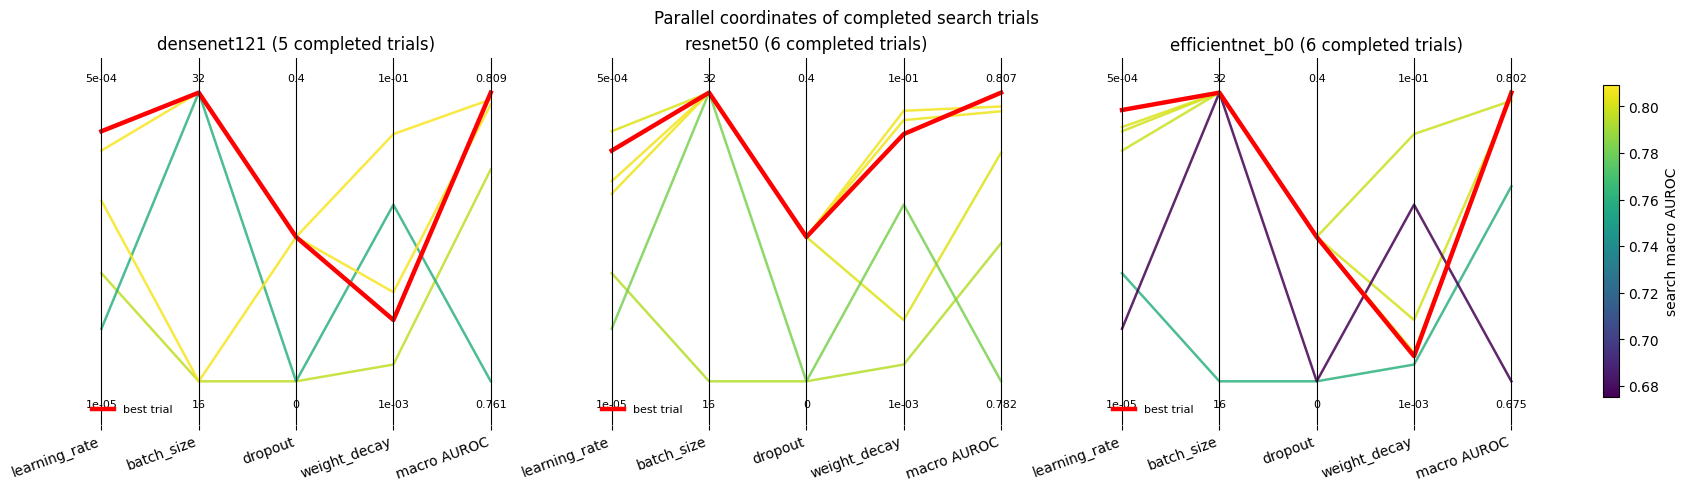

In [16]:
# [Cell 14b] Parallel coordinate chart per backbone
def norm_param(name, values):
    lo, hi = SEARCH_BOUNDS[name]
    v = np.asarray(values, dtype=float)
    if name in LOG_PARAMS:
        return (np.log10(v) - np.log10(lo)) / (np.log10(hi) - np.log10(lo))
    return (v - lo) / (hi - lo)


def fmt_bound(name, v):
    return f"{v:.0e}" if name in LOG_PARAMS else f"{v:g}"


done = trials[trials["state"] == "COMPLETE"]
vmin, vmax = done["value"].min(), done["value"].max()
cmap = plt.get_cmap("viridis")
axis_labels = PARAMS + ["macro AUROC"]
xs = np.arange(len(axis_labels))

fig, axes = plt.subplots(1, len(BACKBONES), figsize=(5.6 * len(BACKBONES), 4.8),
                         sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)
for ax, b in zip(axes, BACKBONES):
    d = done[done["backbone"] == b]
    ax.set_title(f"{b} ({len(d)} completed trials)")
    if d.empty:
        continue
    values = d["value"].to_numpy()
    span = max(values.max() - values.min(), 1e-12)
    ys = np.column_stack([norm_param(p, d[f"params_{p}"]) for p in PARAMS] + [(values - values.min()) / span])
    for row, val in zip(ys, values):
        ax.plot(xs, row, color=cmap((val - vmin) / max(vmax - vmin, 1e-12)), alpha=0.85, lw=1.8)
    ax.plot(xs, ys[values.argmax()], color="red", lw=3.2, label="best trial")
    for x in xs:
        ax.axvline(x, color="k", lw=0.8)
    for x, p in zip(xs[:-1], PARAMS):
        lo, hi = SEARCH_BOUNDS[p]
        ax.text(x, 1.04, fmt_bound(p, hi), ha="center", fontsize=8)
        ax.text(x, -0.09, fmt_bound(p, lo), ha="center", fontsize=8)
    ax.text(xs[-1], 1.04, f"{values.max():.3f}", ha="center", fontsize=8)
    ax.text(xs[-1], -0.09, f"{values.min():.3f}", ha="center", fontsize=8)
    ax.set_xticks(xs)
    ax.set_xticklabels(axis_labels, rotation=20, ha="right")
    ax.set_yticks([])
    ax.set_ylim(-0.15, 1.12)
    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="lower left", fontsize=8, frameon=False)

sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin, vmax), cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=list(axes), label="search macro AUROC", shrink=0.85)
fig.suptitle("Parallel coordinates of completed search trials")
fig.savefig(FIG_DIR / "parallel_coordinates.png", dpi=200, bbox_inches="tight")
plt.show()

densenet121: fANOVA from 5 completed trials (indicative only, fewer than 15 completed trials)
resnet50: fANOVA from 6 completed trials (indicative only, fewer than 15 completed trials)
efficientnet_b0: fANOVA from 6 completed trials (indicative only, fewer than 15 completed trials)


,densenet121,resnet50,efficientnet_b0
learning_rate,0.508,0.255,0.357
batch_size,0.162,0.185,0.149
dropout,0.245,0.437,0.265
weight_decay,0.084,0.123,0.229


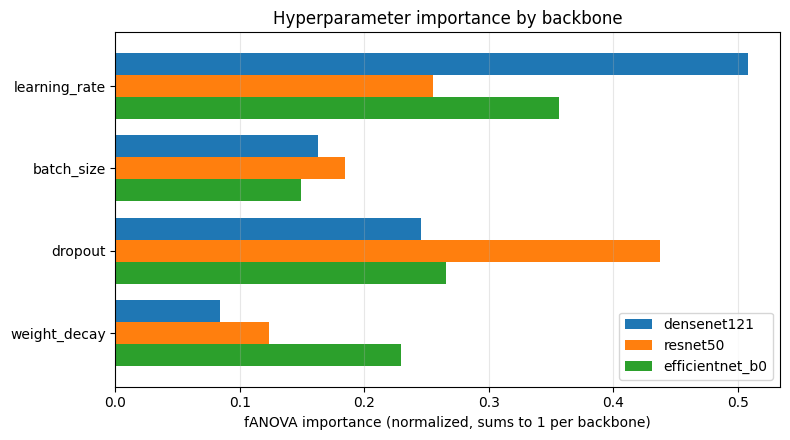

In [17]:
# [Cell 14c] fANOVA importance
from optuna.importance import FanovaImportanceEvaluator, get_param_importances

importances = {}
for b, s in search_studies.items():
    n_done = sum(t.state == optuna.trial.TrialState.COMPLETE for t in s.trials)
    try:
        importances[b] = get_param_importances(s, evaluator=FanovaImportanceEvaluator(seed=SEED), params=PARAMS)
        note = " (indicative only, fewer than 15 completed trials)" if n_done < 15 else ""
        print(f"{b}: fANOVA from {n_done} completed trials{note}")
    except Exception as e:
        print(f"{b}: fANOVA failed with {n_done} completed trials ({type(e).__name__}: {e})")

if importances:
    importance_df = pd.DataFrame(importances).reindex(PARAMS)
    display(importance_df.style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))
    importance_df.to_csv(TABLE_DIR / "fanova_importance.csv")

    ax = importance_df.plot.barh(figsize=(8, 4.5), width=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("fANOVA importance (normalized, sums to 1 per backbone)")
    ax.set_title("Hyperparameter importance by backbone")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fanova_importance.png", dpi=200, bbox_inches="tight")
    plt.show()

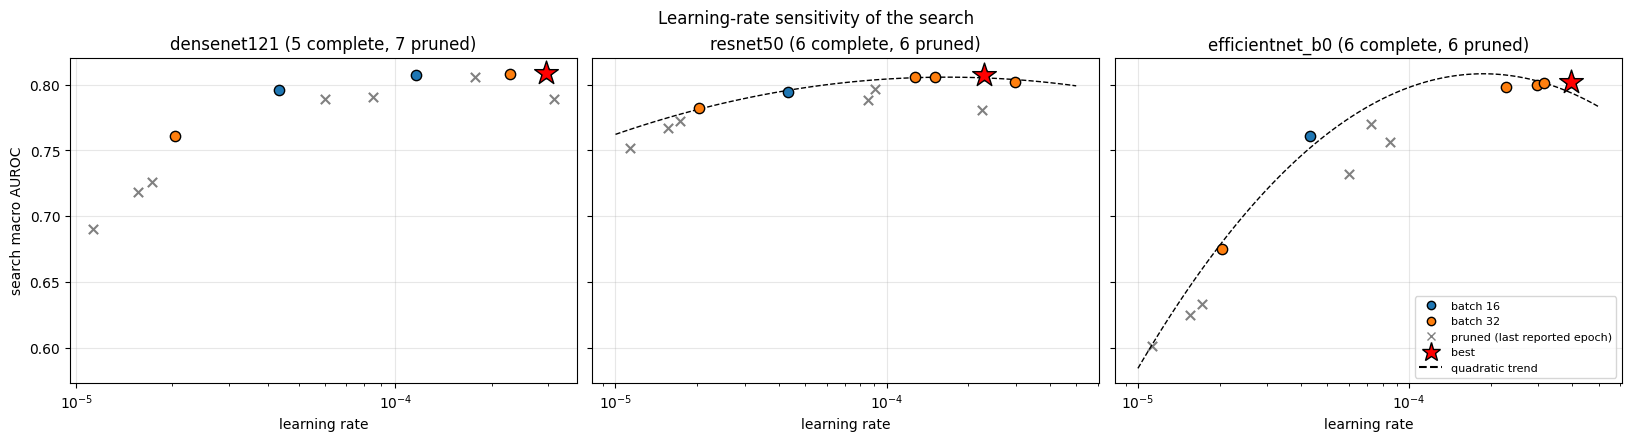

In [18]:
# [Cell 14d] Learning-rate sensitivity curves
from matplotlib.lines import Line2D

bs_color = {16: "tab:blue", 32: "tab:orange"}
fig, axes = plt.subplots(1, len(BACKBONES), figsize=(5.4 * len(BACKBONES), 4.3),
                         sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)

for ax, b in zip(axes, BACKBONES):
    s = search_studies[b]
    comp = [t for t in s.trials if t.state == optuna.trial.TrialState.COMPLETE]
    pruned = [t for t in s.trials if t.state == optuna.trial.TrialState.PRUNED and t.intermediate_values]

    for t in comp:
        ax.scatter(t.params["learning_rate"], t.value, s=55, edgecolor="k", zorder=3,
                   c=bs_color.get(t.params["batch_size"], "gray"))
    if pruned:
        ax.scatter([t.params["learning_rate"] for t in pruned],
                   [t.intermediate_values[max(t.intermediate_values)] for t in pruned],
                   marker="x", c="gray", s=45, zorder=2)
    if len(comp) >= 6:   # quadratic trend in log10(lr); only a rough guide
        x = np.log10([t.params["learning_rate"] for t in comp])
        y = np.array([t.value for t in comp])
        grid = np.linspace(np.log10(SEARCH_BOUNDS["learning_rate"][0]), np.log10(SEARCH_BOUNDS["learning_rate"][1]), 100)
        ax.plot(10 ** grid, np.polyval(np.polyfit(x, y, 2), grid), "--", color="k", lw=1)

    best = s.best_trial
    ax.scatter(best.params["learning_rate"], best.value, marker="*", s=320, c="red", edgecolor="k", zorder=4)
    ax.set_xscale("log")
    ax.set_xlabel("learning rate")
    ax.set_title(f"{b} ({len(comp)} complete, {len(pruned)} pruned)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("search macro AUROC")
handles = [Line2D([], [], marker="o", ls="", mfc="tab:blue", mec="k", label="batch 16"),
           Line2D([], [], marker="o", ls="", mfc="tab:orange", mec="k", label="batch 32"),
           Line2D([], [], marker="x", ls="", color="gray", label="pruned (last reported epoch)"),
           Line2D([], [], marker="*", ls="", mfc="red", mec="k", ms=14, label="best"),
           Line2D([], [], ls="--", color="k", label="quadratic trend")]
axes[-1].legend(handles=handles, fontsize=8, loc="lower right")
fig.suptitle("Learning-rate sensitivity of the search")
fig.savefig(FIG_DIR / "lr_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

In [19]:
# [Cell 15] Save split membership + zip everything for reuse in later sessions
import shutil

pd.concat(
    [d[["patient_id", "shard_path", "shard_index"]].assign(set=name)
     for name, d in split_sets.items()]
).to_csv(OUTPUT_DIR / "split_assignment.csv.gz", index=False)

zip_path = shutil.make_archive(str(OUTPUT_DIR.parent / "nih_tuning_checkpoint"), "zip",
                               root_dir=OUTPUT_DIR.parent, base_dir=OUTPUT_DIR.name)
n_files = sum(1 for p in OUTPUT_DIR.rglob("*") if p.is_file())
print(f"{zip_path}: {Path(zip_path).stat().st_size / 1e6:.0f} MB, {n_files} files")

/kaggle/working/nih_tuning_checkpoint.zip: 130 MB, 28 files
